In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "traffic" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/traffic512final.zip
/content/drive/MyDrive/Colab Notebooks/Traffic Sign Detection and Recognition.ipynb


In [3]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/traffic512final.zip"
extract_path = "/content/traffic_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path)[:10])

Dataset extracted successfully!
['traffic512final']


In [4]:
import os

dataset_path = "/content/traffic_dataset/traffic512final"

for root, dirs, files in os.walk(dataset_path):
    images = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if images:
        print("Folder:", root)
        print("Number of images:", len(images))
        print("Sample images:", images[:5])
        break

Folder: /content/traffic_dataset/traffic512final
Number of images: 1085
Sample images: ['img_0856.jpg', 'img_0391.jpg', 'img_0452.jpg', 'img_0134.jpg', 'img_0939.jpg']


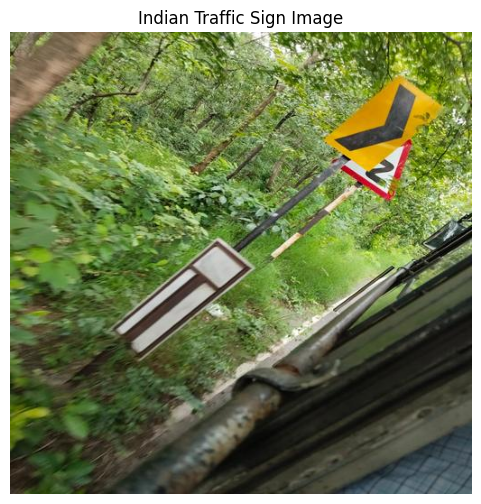

In [5]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/traffic_dataset/traffic512final"

image_name = "img_0856.jpg"
image_path = os.path.join(dataset_path, image_name)

img = Image.open(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("Indian Traffic Sign Image")
plt.axis("off")
plt.show()

In [14]:
import os
import numpy as np
from PIL import Image

dataset_path = "/content/traffic_dataset/traffic512final"

images = [
    f for f in os.listdir(dataset_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

X = []

for file in images:
    img = Image.open(
        os.path.join(dataset_path, file)
    ).convert("RGB")

    img = img.resize((128, 128))
    X.append(np.array(img))

X = np.array(X, dtype="float32") / 255.0

print("Dataset shape:", X.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Dataset shape: (1085, 128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [15]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.21.0
GPU available: False


In [16]:
import os

csv_path = "/content/drive/MyDrive/traffic_vqa_1085.csv"
print("CSV found:", os.path.exists(csv_path))

CSV found: True


In [17]:
import pandas as pd

csv_path = "/content/drive/MyDrive/traffic_vqa_1085.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (1085, 9)

Column names:
['id', 'image_name', 'question', 'answer', 'traffic  sign', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']

First 5 rows:


,id,image_name,question,answer,traffic sign,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,1,img_0001.jpg,What is ahead according to the traffic sign?,Barrier,Cautionary,NaN,NaN,NaN,NaN
1,2,img_0002.jpg,What does this traffic sign indicate?,Barrier,Cautionary,NaN,NaN,NaN,NaN
2,3,img_0003.jpg,What does this traffic sign indicate?,Pedestrian Crossing Ahead,Cautionary,NaN,NaN,NaN,NaN
3,4,img_0004.jpg,What does this traffic sign indicate?,School,Cautionary,NaN,NaN,NaN,NaN
4,5,img_0005.jpg,What does this traffic sign indicate?,Bend,Cautionary,NaN,NaN,NaN,NaN


In [18]:
import pandas as pd
import os

csv_path = "/content/drive/MyDrive/traffic_vqa_1085.csv"
image_folder = "/content/traffic_dataset/traffic512final"

df = pd.read_csv(csv_path)

# Remove empty columns
df = df.dropna(axis=1, how="all")

# Keep rows with image names and answers
df = df.dropna(subset=["image_name", "answer"])

# Keep only images that exist
df = df[
    df["image_name"].apply(
        lambda name: os.path.exists(
            os.path.join(image_folder, str(name))
        )
    )
].copy()

# Clean labels
df["answer"] = df["answer"].astype(str).str.strip()

print("Usable images:", len(df))
print("Unique answers:", df["answer"].nunique())
print("\nMost common answers:")
print(df["answer"].value_counts().head(15))

Usable images: 1085
Unique answers: 165

Most common answers:
answer
Pedestrian Crossing Ahead            80
Directions                           64
Speed Limit                          51
School                               38
yes                                  37
Circle                               33
Humps/Speed breakers                 32
Right-turn                           31
Speed                                28
Hump/Speed breaker                   27
STOP                                 27
right curve ahead                    25
Junction                             23
left curve ahead                     22
Give way to traffic on major road    21
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

# Split images and labels
image_names = df["image_name"].values
labels = df["answer"].values

# 80% training, 20% testing
X_train_names, X_test_names, y_train, y_test = train_test_split(
    image_names,
    labels,
    test_size=0.2,
    random_state=42
)

print("Training images:", len(X_train_names))
print("Testing images:", len(X_test_names))
print("Training labels:", len(set(y_train)))
print("Testing labels:", len(set(y_test)))

Training images: 868
Testing images: 217
Training labels: 156
Testing labels: 77


In [20]:
import numpy as np
from PIL import Image
import os

image_folder = "/content/traffic_dataset/traffic512final"

def load_images(image_names):
    images = []

    for name in image_names:
        path = os.path.join(image_folder, name)
        img = Image.open(path).convert("RGB")
        img = img.resize((64, 64))
        images.append(np.array(img))

    return np.array(images, dtype="float32") / 255.0

X_train = load_images(X_train_names)
X_test = load_images(X_test_names)

print("Training image array:", X_train.shape)
print("Testing image array:", X_test.shape)

Training image array: (868, 64, 64, 3)
Testing image array: (217, 64, 64, 3)


In [21]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)

# Use -1 for labels that were not present in training
label_to_id = {
    label: i for i, label in enumerate(label_encoder.classes_)
}

y_test_encoded = np.array([
    label_to_id.get(label, -1) for label in y_test
])

print("Training classes:", len(label_encoder.classes_))
print("Unseen test labels:", np.sum(y_test_encoded == -1))
print("Example labels:", label_encoder.classes_[:10])

Training classes: 156
Unseen test labels: 9
Example labels: ['1km' '20 km' 'Accident' 'Accident Prone Area' 'Accident Prone Zone'
 'Accident Prone area' 'Accident black spot / Accident-prone area'
 'Added lane from left' 'Arrow' 'Assembly']


In [22]:
import tensorflow as tf

num_classes = len(label_encoder.classes_)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 156)            │        20,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 703,324 (2.68 MB)

 Trainable params: 703,324 (2.68 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = model.fit(
    X_train,
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 233ms/step - accuracy: 0.1700 - loss: 3.5778 - val_accuracy: 0.0862 - val_loss: 4.4072
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 219ms/step - accuracy: 0.2550 - loss: 3.2634 - val_accuracy: 0.1322 - val_loss: 4.4503
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 295ms/step - accuracy: 0.2939 - loss: 3.0823 - val_accuracy: 0.1322 - val_loss: 4.3963
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 218ms/step - accuracy: 0.3213 - loss: 2.8131 - val_accuracy: 0.1034 - val_loss: 4.4425
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 301ms/step - accuracy: 0.3847 - loss: 2.4639 - val_accuracy: 0.1379 - val_loss: 4.5862
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 220ms/step - accuracy: 0.4539 - loss: 2.1354 - val_accuracy: 0.1667 - val_loss: 4.8141
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 319ms/step - accuracy: 0.5072 - loss: 1.9050 - val_accuracy: 0.1437 - val_loss: 5.1782
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 232ms/step - accuracy: 0.5648 - loss: 1.6622 - val_accuracy: 0

In [25]:
import numpy as np

# Select test images with labels seen during training
mask = y_test_encoded != -1

X_test_valid = X_test[mask]
y_test_valid = y_test_encoded[mask]

test_loss, test_accuracy = model.evaluate(
    X_test_valid,
    y_test_valid,
    verbose=0
)

print("Test images:", len(X_test_valid))
print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Test loss:", round(test_loss, 4))

Test images: 208
Test accuracy: 21.63 %
Test loss: 4.7876


In [26]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(len(label_encoder.classes_), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Improved CNN model created!")

Improved CNN model created!


In [27]:

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 156)            │        20,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,884 (507.36 KB)

 Trainable params: 129,884 (507.36 KB)

 Non-trainable params: 0 (0.00 B)